# Predicting which new vulnerabilities attackers will exploit — main report

**On the day a CVE is published, rank it by the chance attackers exploit it within 90 days, so a security team spends
its limited emergency-patching capacity where it matters.**

This notebook is the summary. It runs top to bottom from small cached result tables (no downloads, no model
scoring). The detailed work lives in the appendices:
[03 exploration](03_exploration.ipynb) · [04 baselines](04_baselines.ipynb) · [05a tabular models](05a_tabular_models.ipynb) ·
[05b text models](05b_text_models.ipynb) · [05c fine-tuned transformer](05c_finetuned_transformer.ipynb) ·
[06 test evaluation](06_test_evaluation.ipynb) · [07 explanations and impact](07_explain_and_impact.ipynb).
Decisions and their dates are recorded in `CLAUDE.md`; reproduction steps are in `README.md`.

In [1]:
import os, sys, json, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.environ.setdefault("MPLCONFIGDIR", str(ROOT / ".cache" / "mpl"))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt

TAB, FIG = ROOT / "outputs" / "tables", ROOT / "outputs" / "figures"
BLUE, ORANGE, AQUA, VIOLET, RED, INK, INK2, GRID, SURF = "#2a78d6", "#eb6834", "#1baf7a", "#6250d6", "#d64545", "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
plt.rcParams.update({"figure.facecolor": SURF, "axes.facecolor": SURF, "axes.edgecolor": GRID,
    "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2, "text.color": INK,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "axes.titleweight": "bold",
    "axes.titlesize": 11, "font.size": 9.5})
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 30); pd.set_option("display.max_colwidth", 90)
def T(name, **kw): return pd.read_csv(TAB / f"{name}.csv", **kw)
def save(fig, name): fig.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight")
pt = lambda s: float(str(s).split()[0])
HEAD, ALT = "gradient boosting (headline)", "late fusion (alternative)"
EPSS7 = "EPSS (first score, <=7 d after pub)"
print("cached tables:", len(list(TAB.glob("*.csv"))), "| KEV snapshot:", sorted((ROOT / "data" / "raw").glob("kev_*.csv"))[-1].name)

cached tables: 94 | KEV snapshot: kev_20261120.csv


## 1. Problem and stakeholder
* **Stakeholder:** the Head of Vulnerability Management, reporting to the CISO.
* **Problem:** tens of thousands of new CVEs a year (48,150 in 2025), well under 1% exploited, and capacity for only
  **K emergency patches a month**. Everything else waits for the regular patch cycle.
* **Current policy (assumed):** *emergency-patch every CVE with CVSS ≥ 9*. This is an **assumed stakeholder policy** —
  common severity-based practice — **not verified for a specific organisation**. The conclusions do not depend on it:
  we also compare against CVSS ≥ 7, a stronger "exploitation phrase or CVSS ≥ 9" rule, CVSS ranking, a hindsight CVSS
  rule and EPSS, each at its own capacity, and show **recall across every capacity K from 10 to 1,000 patches a month**
  (Section 9): the model leads every day-0 rule at every K.
* **Label:** a CVE is "exploited" if CISA adds it to the **Known Exploited Vulnerabilities (KEV)** catalogue within
  **90 days** of its NVD publication (KEV before publication counts too).
* **Impact metric:** share of exploited CVEs caught at the same capacity (**recall@K per month**), and analyst hours.

,cves,positives,rate_%
year,,,
2022,25073,85,0.34
2023,28816,121,0.42
2024,39953,113,0.28
2025,48150,159,0.33
2026,54411,135,0.25


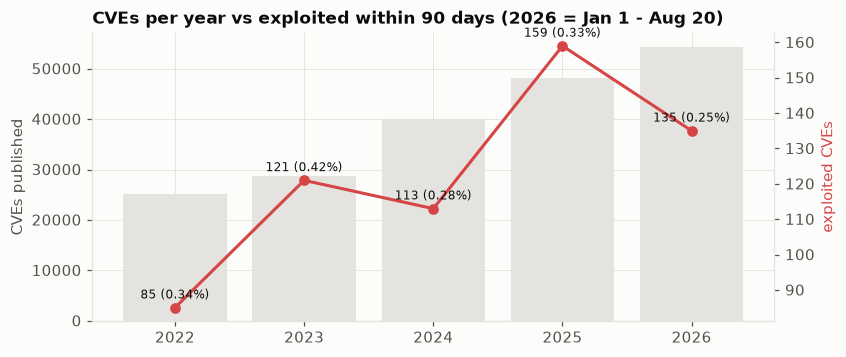

In [2]:
py = T("03_positives_by_year")
display(py.set_index("year"))
fig, ax = plt.subplots(figsize=(8, 3.4)); ax2 = ax.twinx()
ax.bar(py["year"].astype(str), py["cves"], color=GRID, label="CVEs published")
ax2.plot(py["year"].astype(str), py["positives"], "o-", color=RED, lw=2, label="exploited within 90 d (KEV)")
ax.set_ylabel("CVEs published"); ax2.set_ylabel("exploited CVEs", color=RED); ax2.grid(False); ax2.spines["right"].set_visible(True)
ax.set_title("CVEs per year vs exploited within 90 days (2026 = Jan 1 - Aug 20)", loc="left")
for x, (c, p, r) in enumerate(zip(py["cves"], py["positives"], py["rate_%"])): ax2.annotate(f"{p} ({r:.2f}%)", (x, p), xytext=(0, 6), textcoords="offset points", ha="center", fontsize=8)
save(fig, "00_01_problem")

**Takeaway**: **196,403 CVEs were published from 2022 to Aug 2026, and only 613 (0.31%, about 1 in 320) were exploited within 90 days.** Volume doubled from 25,073 (2022) to 48,150 (2025), and 2026 is on track for ~85,000. Exploited CVEs per year stayed in the low hundreds (85–159). The emergency list must stay small while the haystack grows: the core business problem.

## 2. The evolution of cybersecurity (descriptive only)
All years allowed; **no modelling choice uses this section**. NVD data cover CVEs published 2022-01-01 → 2026-08-20
(the label cutoff); the KEV catalogue reaches back to CVEs from 2002, so it gives the long view.

,CVEs,CNA CVSS >= 9 %,no CNA score,cvss_source=other %
year,,,,
2022,25073,3.7,57.4,16.3
2023,28816,4.7,39.9,20.2
2024,39953,5.4,30.2,24.6
2025,48150,5.9,24.3,18.1
2026,54411,8.9,19.4,14.6


,kev_listed,median_days,<= 0 d %,<= 7 d %,<= 30 d %,<= 90 d % (= label 1)
year,,,,,,
2022,131,24.0,29.8,38.9,51.9,64.9
2023,166,6.0,27.7,52.4,64.5,72.9
2024,161,13.0,24.8,48.4,59.0,70.2
2025,198,8.0,24.7,49.0,63.6,80.3
2026,150,7.5,24.0,50.0,71.3,90.0


share of exploited CVEs (%) by vendor and year (top 10 vendors of exploited CVEs, 'cna:' = vendor missing):


year,2022,2023,2024,2025,2026
vendor,,,,,
microsoft,23.5,18.2,21.2,17.6,17.0
google,11.8,6.6,9.7,6.3,4.4
apple,10.6,15.7,5.3,5.0,1.5
fortinet,2.4,2.5,2.6,4.4,3.0
ivanti,0.0,2.5,7.1,4.4,3.7
cisco,7.1,3.3,3.5,3.8,9.6
adobe,1.2,3.3,0.9,1.3,2.2
cna:cve@mitre.org,12.9,11.6,7.1,1.3,0.0
cna:security@vmware.com,4.7,0.8,2.6,1.3,0.0


,kev_entries,ransomware_pct,median_years_cve_to_kev
cve_year,,,
2016,60,16.7,6.0
2017,86,23.3,5.0
2018,89,37.1,4.0
2019,119,34.5,3.0
2020,146,13.0,1.0
2021,216,28.2,0.0
2022,132,28.0,0.0
2023,166,22.3,0.0
2024,166,23.5,0.0


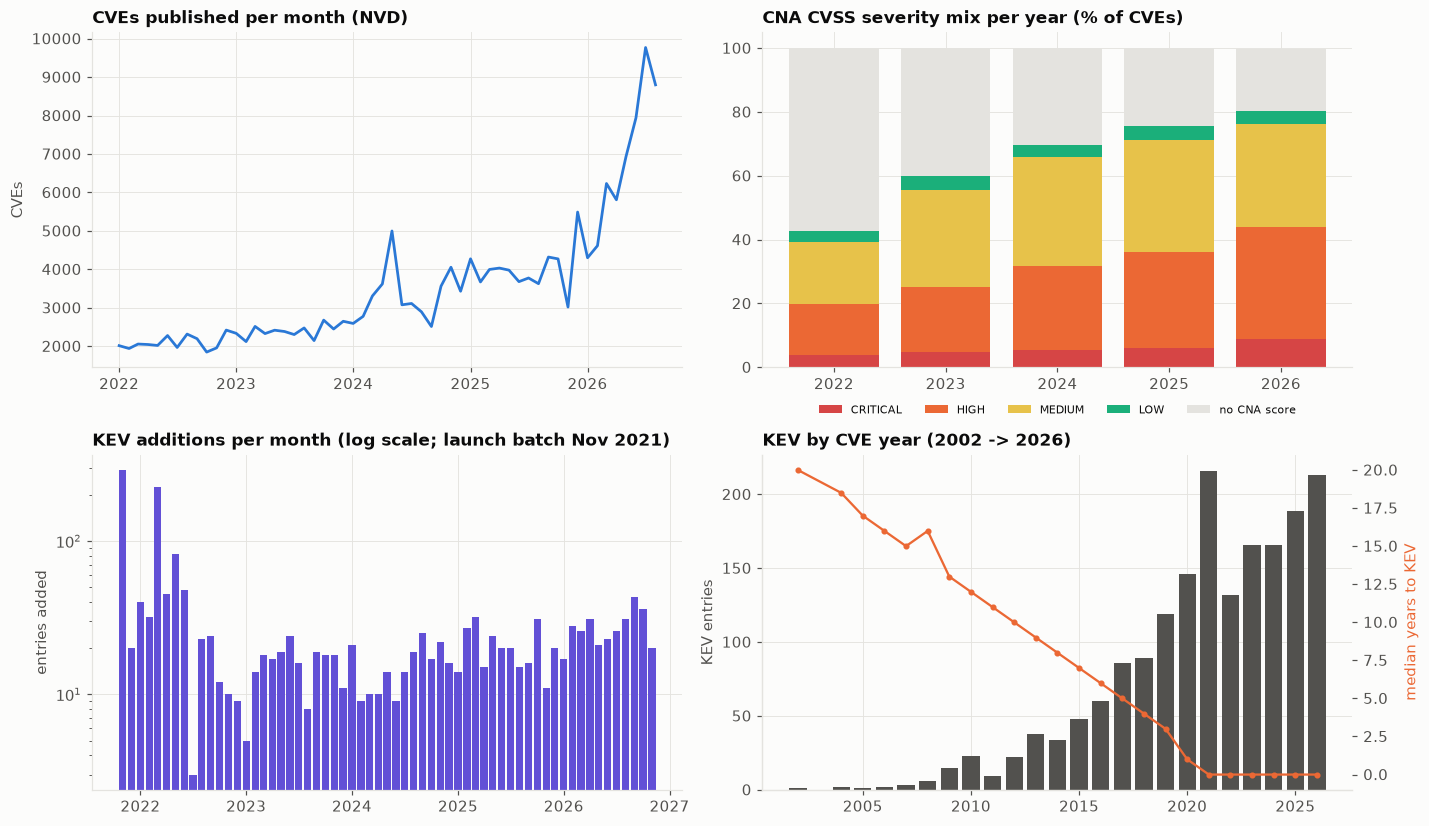

In [3]:
mo = T("00_evo_monthly"); mix = T("00_evo_cvss_mix").set_index("year"); kbm = T("00_kev_by_month"); kcy = T("00_kev_by_cve_year")
ven = T("00_evo_vendors"); dtk = T("00_evo_days_to_kev").set_index("year")
fig, axes = plt.subplots(2, 2, figsize=(13, 7.6))
a = axes[0, 0]; a.plot(pd.PeriodIndex(mo["month"], freq="M").to_timestamp(), mo["cves"], color=BLUE, lw=1.8)
a.set_title("CVEs published per month (NVD)", loc="left"); a.set_ylabel("CVEs")
a = axes[0, 1]; sev = ["CRITICAL", "HIGH", "MEDIUM", "LOW", "no CNA score"]
bottom = np.zeros(len(mix))
for s, c in zip(sev, [RED, ORANGE, "#e7c24a", AQUA, GRID]):
    a.bar(mix.index.astype(str), mix[s], bottom=bottom, color=c, label=s); bottom += mix[s].to_numpy()
a.set_title("CNA CVSS severity mix per year (% of CVEs)", loc="left"); a.legend(frameon=False, fontsize=7.5, ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.08))
a = axes[1, 0]; a.bar(pd.PeriodIndex(kbm["dateAdded"], freq="M").to_timestamp(), kbm["kev_additions"], width=25, color=VIOLET)
a.set_yscale("log"); a.set_title("KEV additions per month (log scale; launch batch Nov 2021)", loc="left"); a.set_ylabel("entries added")
a = axes[1, 1]; a.bar(kcy["cve_year"], kcy["kev_entries"], color=INK2, label="KEV entries by CVE-ID year")
a2 = a.twinx(); a2.plot(kcy["cve_year"], kcy["median_years_cve_to_kev"], "o-", color=ORANGE, ms=3, label="median years CVE-ID year -> KEV"); a2.grid(False)
a.set_title("KEV by CVE year (2002 -> 2026)", loc="left"); a.set_ylabel("KEV entries"); a2.set_ylabel("median years to KEV", color=ORANGE)
fig.tight_layout(); save(fig, "00_02_evolution")
display(mix[["CVEs", "CNA CVSS >= 9 %", "no CNA score", "cvss_source=other %"]].round(1))
display(dtk)
vp = ven.pivot(index="vendor", columns="year", values="share of exploited %").round(1)
print("share of exploited CVEs (%) by vendor and year (top 10 vendors of exploited CVEs, 'cna:' = vendor missing):"); display(vp.sort_values(2025, ascending=False))
display(kcy[kcy["cve_year"] >= 2016].set_index("cve_year"))

**Takeaway**: **CVE volume is accelerating** (about 2,100 a month in 2022, ~6,800 a month in 2026). **CNAs now score most CVEs themselves**: CVEs without a CNA CVSS fell from 57% to 19%. **'Critical' scores are inflating**: CNA CVSS ≥ 9 went from 3.7% to 8.9% of CVEs, so a CVSS ≥ 9 policy grows from ~80 to ~600 patches a month. **Exploitation is getting faster and more visible**: among KEV-listed CVEs, the share listed within 30 days rose from 52% (2022) to 71% (2026, partly because 2026 has less time to be listed late). About a quarter are listed on or before publication day. **KEV is now mostly about new CVEs**: the median CVE added in the 2017 vintage waited 5 years, but CVEs since 2021 are listed in the same year. Microsoft is consistently ~17–24% of exploited CVEs. Apple and MITRE-published (vendor unknown) CVEs faded, and Cisco rose to 9.6% in 2026. Ransomware links are 20% of the catalogue overall, highest for 2018–2019 CVEs (35–37%).

## 3. Data acquisition
| source | what | how | snapshot |
|---|---|---|---|
| **NVD API 2.0** | every CVE published since 2022-01-01: CNA, description, CWE, vendor/product, CVSS (with the source of each score) | `src/build_cve_dataset.py`, 90-day windows, paging, retries, cached per window | downloaded 2026-11-20 |
| **NVD change history** | first recorded version of descriptions / CVSS for the 919-CVE audit sample + 147 phrase CVEs | `src/nvd_history.py` | 2026-11-20 |
| **CISA KEV** | the label (dateAdded), KEV-history features (entries before publication only), ransomware flag (evaluation only) | one CSV download | `data/raw/kev_20261120.csv` (latest entry 2026-11-18) |
| **FIRST EPSS** | benchmark only: first score on/after publication (≤ 7 days) for val + test | `src/epss.py`, api.first.org | queried 2026-11-21 |

**Right-censoring:** CVEs published less than 90 days before the KEV snapshot are dropped (label not knowable), so
labels are complete up to **2026-08-20**. A newer KEV would only move that cutoff.

In [4]:
kev = pd.read_csv(sorted((ROOT / "data" / "raw").glob("kev_*.csv"))[-1])
print(f"KEV snapshot: {len(kev):,} entries, dateAdded {kev['dateAdded'].min()} -> {kev['dateAdded'].max()}, "
      f"CVE years {kev['cveID'].str[4:8].min()} -> {kev['cveID'].str[4:8].max()}, ransomware 'Known' {kev['knownRansomwareCampaignUse'].eq('Known').mean():.1%}")
print(f"dataset: {py['cves'].sum():,} CVEs (2022-01-01 -> 2026-08-20), {py['positives'].sum()} exploited within 90 days ({py['positives'].sum() / py['cves'].sum():.2%})")
cov = T("06_epss_coverage"); print(f"EPSS (test): first score on publication day for {cov.iloc[0]['share of CVEs %']:.1f}% of CVEs, next day for {cov.iloc[1]['share of CVEs %']:.1f}%")

KEV snapshot: 1,786 entries, dateAdded 2021-11-03 -> 2026-11-18, CVE years 2002 -> 2026, ransomware 'Known' 20.2%
dataset: 196,403 CVEs (2022-01-01 -> 2026-08-20), 613 exploited within 90 days (0.31%)
EPSS (test): first score on publication day for 29.9% of CVEs, next day for 69.5%


**Takeaway**: Four sources, all dated: **NVD** (196,403 CVEs after removing those still inside the 90-day label window), **NVD change history** (for auditing day-0 values), **CISA KEV** snapshot of 2026-11-20 (1,786 entries; labels complete to 2026-08-20) and **FIRST EPSS** (benchmark only). EPSS is mostly a next-day signal: on test only 29.9% of CVEs had a score on publication day and 69.5% the next day.

## 4. Leakage hunt
NVD returns **today's** version of each record, and some fields are added *because* a CVE was exploited. Each leak
below was found in the data, fixed before modelling, and checked with numbers (details: notebooks 03 and 05b,
`CLAUDE.md` Decisions 4, 9, 10).

,evidence,fix,before -> after
leak,,,
CVSS from CISA-ADP / NVD (added after publication),2022Q1: 3.4% of CVEs vs 46.4% of exploited CVEs have an ADP score (ADP did not exist yet),CVSS features from the CNA's own score only (Decision 9),35.1% at 306/mo (fallback) -> 21.9% at 110/mo (CNA only)
CWE assigned later by NVD analysts,55.4% of exploited train CVEs got their CWE from NVD (rate 0.45% vs 0.28% for CNA CWEs),CNA CWE only (Decision 10a),feature definition changed before any model was fit
"descriptions edited after exploitation (""exploited in the wild"" added)",edited: 30.4% of exploited vs 12.3% of other CVEs (history sample),description_day0: phrases not in the first recorded version removed (Decision 10c),text model on earliest vs today's text: Spearman 0.977; val recall unchanged or higher
vendor KEV history counting future / own KEV entries,a vendor's KEV count today includes entries added after the CVE was published,"only entries added BEFORE publication, never the CVE's own (guard by design)",val recall@110: guarded 47.1 vs own-entry leak 45.6 vs naive 35.0 (no inflation here)
"random train/test split (twin CVEs, future data)",51% of random-split val positives had an exploited same-vendor+month twin in train,split by publication date; walk-forward checks (Decision 6),same model: random split 59.1% vs date split 38.2% recall
CNA CVSS changed later by the CNA itself (residual),5.5% of exploited vs 1.9% of other CVEs had their CNA vector changed later,not fixable from day-0 data; sensitivity run with first known vector,selection score 47.4 -> 46.6 (gradient boosting)


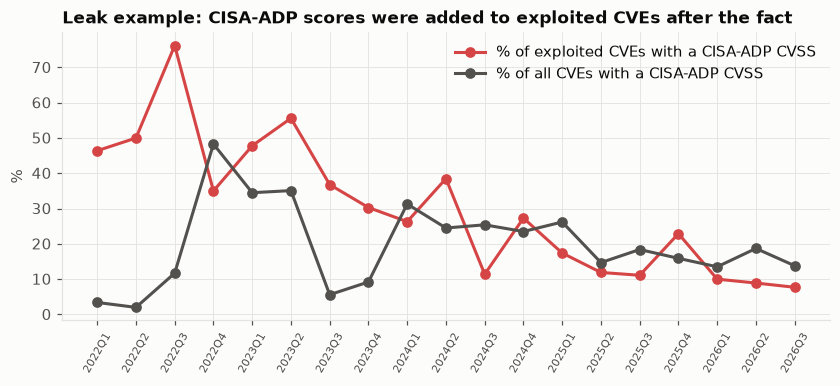

In [5]:
adp = T("00_leak_adp_by_quarter"); b = T("03b_train_baselines_cna_vs_fallback"); cwe = T("03c_train_cwe_source").set_index("cwe_fallback_source")
ed = T("03e_history_description_changes").set_index("label"); sens = T("05b_sensitivity_original_text"); kh = T("00_leak_kev_history")
rs = T("04_random_vs_date_split"); st = T("05d_cna_cvss_stability") if (TAB / "05d_cna_cvss_stability.csv").exists() else None
leaks = pd.DataFrame([
    {"leak": "CVSS from CISA-ADP / NVD (added after publication)", "evidence": f"2022Q1: {adp.iloc[0]['% of CVEs with ADP CVSS']:.1f}% of CVEs vs {adp.iloc[0]['% of exploited with ADP CVSS']:.1f}% of exploited CVEs have an ADP score (ADP did not exist yet)",
     "fix": "CVSS features from the CNA's own score only (Decision 9)", "before -> after (train, CVSS>=9 rule)": f"{b.iloc[1]['recall_%']}% at {b.iloc[1]['patches/month']}/mo (fallback) -> {b.iloc[0]['recall_%']}% at {b.iloc[0]['patches/month']}/mo (CNA only)"},
    {"leak": "CWE assigned later by NVD analysts", "evidence": f"{cwe.loc['nvd', 'share_of_pos_%']}% of exploited train CVEs got their CWE from NVD (rate {cwe.loc['nvd', 'rate_%']}% vs {cwe.loc['cna', 'rate_%']}% for CNA CWEs)",
     "fix": "CNA CWE only (Decision 10a)", "before -> after (train, CVSS>=9 rule)": "feature definition changed before any model was fit"},
    {"leak": "descriptions edited after exploitation (\"exploited in the wild\" added)", "evidence": f"edited: {ed.loc['positives (all)', 'desc_changed_%']}% of exploited vs {ed.loc['negatives (sample)', 'desc_changed_%']}% of other CVEs (history sample)",
     "fix": "description_day0: phrases not in the first recorded version removed (Decision 10c)", "before -> after (train, CVSS>=9 rule)": f"text model on earliest vs today's text: Spearman {sens.iloc[0]['Spearman (sample CVEs)']:.3f}; val recall unchanged or higher"},
    {"leak": "vendor KEV history counting future / own KEV entries", "evidence": "a vendor's KEV count today includes entries added after the CVE was published",
     "fix": "only entries added BEFORE publication, never the CVE's own (guard by design)", "before -> after (train, CVSS>=9 rule)": f"val recall@110: guarded {kh.iloc[0]['val recall@110 %']} vs own-entry leak {kh.iloc[1]['val recall@110 %']} vs naive {kh.iloc[2]['val recall@110 %']} (no inflation here)"},
    {"leak": "random train/test split (twin CVEs, future data)", "evidence": f"{rs.iloc[1].iloc[-1]:.0f}% of random-split val positives had an exploited same-vendor+month twin in train",
     "fix": "split by publication date; walk-forward checks (Decision 6)", "before -> after (train, CVSS>=9 rule)": f"same model: random split {rs.iloc[1]['recall@3.4% of monthly CVEs']}% vs date split {rs.iloc[0]['recall@3.4% of monthly CVEs']}% recall"},
    {"leak": "CNA CVSS changed later by the CNA itself (residual)", "evidence": "5.5% of exploited vs 1.9% of other CVEs had their CNA vector changed later",
     "fix": "not fixable from day-0 data; sensitivity run with first known vector", "before -> after (train, CVSS>=9 rule)": "selection score 47.4 -> 46.6 (gradient boosting)"}]).set_index("leak")
leaks.columns = ["evidence", "fix", "before -> after"]
display(leaks)
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.plot(adp["published"], adp["% of exploited with ADP CVSS"], "o-", color=RED, lw=2, label="% of exploited CVEs with a CISA-ADP CVSS")
ax.plot(adp["published"], adp["% of CVEs with ADP CVSS"], "o-", color=INK2, lw=2, label="% of all CVEs with a CISA-ADP CVSS")
ax.set_ylabel("%"); ax.tick_params(axis="x", rotation=60, labelsize=7.5); ax.legend(frameon=False)
ax.set_title("Leak example: CISA-ADP scores were added to exploited CVEs after the fact", loc="left"); save(fig, "00_03_leak_adp")

**Takeaway**: **Five things in today's NVD/KEV data would have leaked the answer.** (1) **CISA-ADP CVSS scores** were back-filled mostly for exploited CVEs: in 2022Q1, 46% of exploited vs 3.4% of all CVEs. Using them makes the CVSS ≥ 9 rule look like 35.1% recall instead of the honest 21.9% on train. Fix: the CNA's own score only. (2) **NVD-assigned CWEs** cover 55% of exploited train CVEs. Fix: CNA CWE only. (3) **Descriptions are edited after exploitation** (30.4% of exploited vs 12.3% of other CVEs). Fix: remove phrases not in the first recorded version; re-scoring with the earliest text changed rankings very little (Spearman 0.977). (4) **Vendor KEV history** must count only entries added before publication: guarded by design. Here the leaky variants did not inflate validation (45.6% own-entry, 35.0% naive vs 47.1%), so this is a correctness guarantee rather than a number that moved. (5) **A random split** inflates recall from 38.2% to 59.1% for the same model: 51% of random-split validation positives had an exploited twin (same vendor and month) in train. **Residual, unfixable from day-0 data:** CNAs later revised their own CVSS for 5.5% of exploited vs 1.9% of other CVEs; it costs 0.8 points when tested.

## 5. Task, splits and metric
* **Task:** supervised binary classification on publication-day information only; output used as a **monthly ranking**.
* **Split by date** (never random): train 2022-01 → 2024-06 (74,268 CVEs / 251 exploited), validation 2024-07 → 2024-12
  (19,574 / 68), **test 2025-01 → 2026-08-20 (102,561 / 294), opened once** in Phase 6. Walk-forward folds inside dev:
  2022 → 2023 and 2022–23 → 2024-H1.
* **Metric: recall@K per calendar month** — each month, patch the top K CVEs; recall = exploited CVEs caught / all
  exploited. K = **110** = the monthly capacity of the CVSS ≥ 9 (CNA) rule in train; K = **305** = the hindsight
  (fallback-CVSS) rule's capacity. Both fixed from train before modelling; the full recall-vs-K curve is always shown.
* **Uncertainty:** paired within-month Poisson bootstrap (2,000 resamples) → 95% CIs and P(model better).
  PR-AUC is secondary. Selection = mean recall@110 over the three dev periods (never validation alone).

In [6]:
split = pd.DataFrame({"period": ["train", "validation", "test"], "dates": ["2022-01 -> 2024-06", "2024-07 -> 2024-12", "2025-01 -> 2026-08-20"],
                      "CVEs": [74268, 19574, 102561], "exploited": [251, 68, 294]})
split["rate %"] = (100 * split["exploited"] / split["CVEs"]).round(3)
split["CVEs / month"] = (split["CVEs"] / [30, 6, 20]).round(0)
split["K=110 as % of a month"] = (100 * 110 / split["CVEs / month"]).round(1)
display(split.set_index("period"))

,dates,CVEs,exploited,rate %,CVEs / month,K=110 as % of a month
period,,,,,,
train,2022-01 -> 2024-06,74268,251,0.338,2476.0,4.4
validation,2024-07 -> 2024-12,19574,68,0.347,3262.0,3.4
test,2025-01 -> 2026-08-20,102561,294,0.287,5128.0,2.1


**Takeaway**: Splitting by date makes the task harder and more honest. Test months are twice as large as train months (5,128 vs 2,476 CVEs). The fixed K = 110 covers 4.4% of a train month but only 2.1% of a test month. Recall@K per month with a paired bootstrap gives a CI for every comparison. Test was opened once.

## 6. Baselines and business rules (validation, day-0 information)

,type,rule patches/month,rule recall %,recall@110 % [95% CI],recall@305 % [95% CI],PR-AUC
method,,,,,,
random,benchmark,NaN,NaN,3.5,9.6,NaN
CVSS (CNA) ranking,benchmark,196.0,33.8,23.7 [13–33],38.3 [27–50],0.011
"phrase, then CVSS (CNA)",benchmark,197.0,38.2,28.1 [17–38],42.7 [31–55],0.069
generous CVSS (fallback) ranking,"benchmark (hindsight, upper bound)",313.0,41.2,15.1 [6–25],38.5 [27–51],0.011
CVSS>=7 (CNA) rule,benchmark,1089.0,64.7,= CVSS (CNA) ranking,= CVSS (CNA) ranking,NaN
preview: logistic regression (day-0 tabular),model preview (Phase 5),NaN,NaN,36.8,67.6,0.108


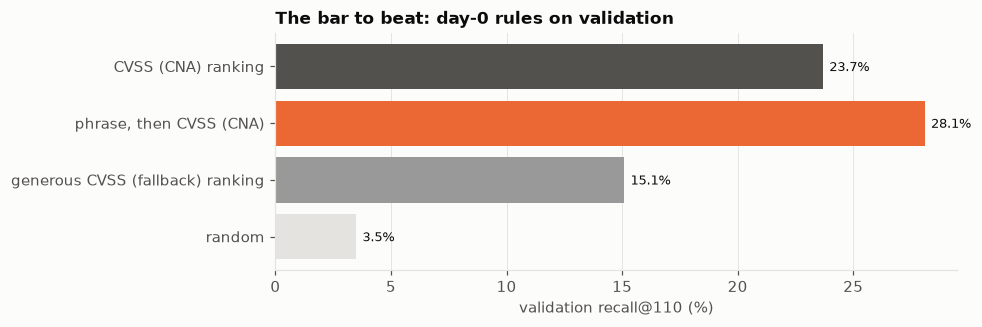

In [7]:
bv = T("04_val_comparison").set_index("method"); display(bv)
order = ["CVSS (CNA) ranking", "phrase, then CVSS (CNA)", "generous CVSS (fallback) ranking"]
fig, ax = plt.subplots(figsize=(8, 2.8))
v = [pt(bv.loc[m, "recall@110 % [95% CI]"]) for m in order] + [pt(bv.loc["random", "recall@110 % [95% CI]"])]
ax.barh(order + ["random"], v, color=[INK2, ORANGE, "#999999", GRID]); ax.invert_yaxis(); ax.grid(axis="y", visible=False)
for i, x in enumerate(v): ax.annotate(f"{x:.1f}%", (x, i), xytext=(4, -3), textcoords="offset points", fontsize=8.5)
ax.set_xlabel("validation recall@110 (%)"); ax.set_title("The bar to beat: day-0 rules on validation", loc="left"); save(fig, "00_04_baselines")

**Takeaway**: **On validation, the best rule a careful team could run today ('exploitation phrase first, then CNA CVSS') catches 28.1% [17–38] of exploited CVEs with 110 patches a month.** Plain CVSS ranking catches 23.7%, random 3.5%. That is the bar. Using hindsight CVSS (ADP-filled) does *not* help at K = 110 (15.1%), which shows the late scores are not a shortcut once ranking is honest.

## 7. Models: tabular ML and deep learning on text
* **Supervised, hand-built features:** logistic regression and gradient boosting (HistGradientBoosting) on CNA CVSS,
  CNA, vendor, CWE, description length, day-0 exploitation phrase and vendor/product KEV history.
* **Pretrained (self-supervised) representations:** sentence embeddings of the day-0 description from MiniLM / BGE —
  encoders pretrained without our labels (self-supervised transfer learning), then a supervised head (logistic
  regression or small MLP with early stopping, 5 seeds).
* **Fine-tuned transformer:** MiniLM fine-tuned end-to-end on our labels (MPS GPU).
* **Combinations:** tabular + text MLP; gradient boosting + out-of-fold text score; **late fusion** (average of
  within-month ranks of gradient boosting and the text MLP).

All chosen by the same rule: mean recall@110 over WF 2023, WF 2024-H1 and validation.

,learning,representation,selection (3-period mean),worst period,val recall@110 [CI],val recall@305 [CI]
method,,,,,,
gradient boosting,"supervised, tabular",hand-built features,47.4,39.7,47.1 [36–60],67.6 [57–79]
late fusion: boosting + text MLP,rank fusion,features + embeddings,46.7,42.6,42.6 [30–55],64.7 [54–77]
gradient boosting + OOF text score,"supervised, tabular + text",features + embeddings,45.3,42.1,42.6 [32–55],63.2 [51–74]
tabular + text MLP,"supervised, tabular + text",features + embeddings,44.8,38.8,38.2 [27–50],75.0 [63–84]
"text MLP (MiniLM embeddings, 5 seeds)",pretrained (self-supervised) + supervised head,frozen sentence embeddings,39.5,30.6,32.4 [20–43],50.0 [38–63]
text LR (MiniLM embeddings),pretrained (self-supervised) + supervised head,frozen sentence embeddings,39.2,23.5,23.5 [14–34],45.6 [33–58]
logistic regression,"supervised, tabular",hand-built features,37.8,28.9,30.9 [21–43],58.8 [46–70]
fine-tuned MiniLM (2 seeds),pretrained + supervised fine-tuning,transformer weights updated,34.6,26.5,25.0 [15–36],57.4 [44–68]
"phrase, then CVSS (CNA)",best day-0 rule,-,34.1,28.1,28.1 [17–38],42.7 [31–55]


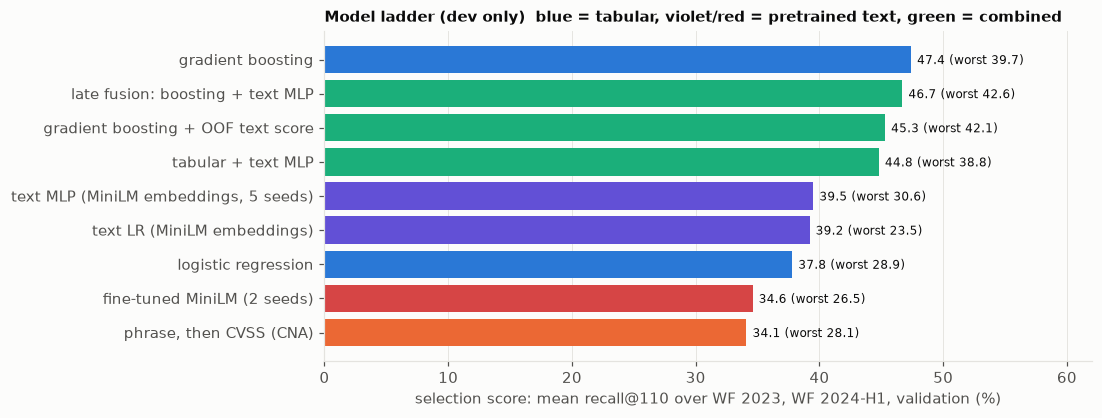

In [8]:
a5 = T("05a_comparison").set_index("method"); b5 = T("05b_comparison").set_index("method"); c5 = T("05c_comparison").set_index("method")
rows = [
 ("phrase, then CVSS (CNA)", "best day-0 rule", "-", b5.loc["phrase, then CVSS (CNA)"]),
 ("logistic regression", "supervised, tabular", "hand-built features", None),
 ("gradient boosting", "supervised, tabular", "hand-built features", b5.loc["gradient boosting (05a)"]),
 ("text LR (MiniLM embeddings)", "pretrained (self-supervised) + supervised head", "frozen sentence embeddings", b5.loc["text LR"]),
 ("text MLP (MiniLM embeddings, 5 seeds)", "pretrained (self-supervised) + supervised head", "frozen sentence embeddings", b5.loc["text MLP (5 seeds)"]),
 ("fine-tuned MiniLM (2 seeds)", "pretrained + supervised fine-tuning", "transformer weights updated", c5.loc["fine-tuned MiniLM (lr1e-5_full, 2 seeds)"]),
 ("tabular + text MLP", "supervised, tabular + text", "features + embeddings", b5.loc["(a) tabular+text MLP (5 seeds)"]),
 ("gradient boosting + OOF text score", "supervised, tabular + text", "features + embeddings", b5.loc["(b) gradient boosting + OOF text score"]),
 ("late fusion: boosting + text MLP", "rank fusion", "features + embeddings", b5.loc["(c) late fusion: gradient boosting + text MLP (5 seeds)"])]
out = []
for name, kind, rep, r in rows:
    if r is None:
        r = a5.loc["logistic regression"]; sel = np.mean([r["WF 2023"], r["WF 2024-H1"], pt(r["val recall@110 [CI]"])])
        out.append({"method": name, "learning": kind, "representation": rep, "selection (3-period mean)": round(sel, 1), "worst period": min(r["WF 2023"], r["WF 2024-H1"], pt(r["val recall@110 [CI]"])),
                    "val recall@110 [CI]": r["val recall@110 [CI]"], "val recall@305 [CI]": r["val recall@305 [CI]"]})
        continue
    v110 = r.get("val recall@110 [CI] (ensemble for nets)", r.get("val recall@110 [CI]")); v305 = r.get("val recall@305 [CI] (ensemble for nets)", r.get("val recall@305 [CI]"))
    out.append({"method": name, "learning": kind, "representation": rep, "selection (3-period mean)": r["selection (3-period mean)"],
                "worst period": r.get("worst period", r.get("worst period")), "val recall@110 [CI]": v110, "val recall@305 [CI]": v305})
ladder = pd.DataFrame(out).set_index("method").sort_values("selection (3-period mean)", ascending=False)
display(ladder); ladder.to_csv(TAB / "00_model_ladder.csv")
fig, ax = plt.subplots(figsize=(9, 3.9))
col = {"best day-0 rule": ORANGE, "supervised, tabular": BLUE, "pretrained (self-supervised) + supervised head": VIOLET,
       "pretrained + supervised fine-tuning": RED, "supervised, tabular + text": AQUA, "rank fusion": AQUA}
lad = ladder.iloc[::-1]
ax.barh(lad.index, lad["selection (3-period mean)"], color=[col[k] for k in lad["learning"]])
for i, (s, w) in enumerate(zip(lad["selection (3-period mean)"], lad["worst period"])): ax.annotate(f"{s:.1f} (worst {w:.1f})", (s, i), xytext=(4, -3), textcoords="offset points", fontsize=8)
ax.set_xlim(0, 62); ax.grid(axis="y", visible=False); ax.set_xlabel("selection score: mean recall@110 over WF 2023, WF 2024-H1, validation (%)")
ax.set_title("Model ladder (dev only)  blue = tabular, violet/red = pretrained text, green = combined", loc="left", fontsize=10)
save(fig, "00_05_model_ladder")

**Takeaway**: **Gradient boosting on hand-built day-0 features is the best single model (selection 47.4%, validation 47.1% [36–60])**, 13 points above the best rule (34.1% selection). Text helps as a *second opinion*, not alone. Pretrained sentence embeddings with a supervised head reach 39.2–39.5%, above the rule but below tabular models. Fine-tuning MiniLM end-to-end on 251 positives did *worse* (34.6%) than the frozen pretrained encoder (overfitting). Late fusion of gradient boosting and the text MLP has the best worst period (42.6%) at a near-identical mean (46.7%). Self-supervised pretraining transfers useful language knowledge, but with a few hundred labels the frozen representation beats fine-tuning.

## 8. Model selection — fixed before the test set was opened
* **Decision 11 (2026-11-20):** highest selection score wins; within 2 points, the better worst period. That picked
  late fusion (46.7, worst 42.6) over gradient boosting (47.4, worst 39.7).
* **Pre-test checks** then showed the fusion leans on uncertain day-0 phrases (−2.0 points when removed; gradient
  boosting +0.4) and that gradient boosting was better on validation (47.1 vs 42.6) and on the "not yet in KEV"
  subset (52.5 vs 35.0).
* **Decision 12 (2026-11-21, dev evidence only, before any test label was seen):** **headline = gradient boosting**;
  late fusion = reported alternative. The test protocol (models, K, metrics, comparators, analyses) was written into
  `CLAUDE.md` before the test run, and a dry run on validation reproduced Phase 5 exactly.

,wf_2023@110,wf_2024h1@110,val@110,selection,worst
model,,,,,
late fusion,46.3,51.1,42.6,46.7,42.6
gradient boosting,39.7,55.6,47.1,47.4,39.7
"phrase, then CVSS (CNA)",39.3,34.9,28.1,34.1,28.1


selection  worst
variant                                 model                              
base (as in 05b)                        late fusion             46.7   42.6
                                        gradient boosting       47.4   39.7
uncertain phrases removed (21 CVEs)     late fusion             44.7   39.7
                                        gradient boosting       47.8   37.2
CNA CVSS = first known vector (16 CVEs) late fusion             45.9   41.2
                                        gradient boosting       46.6   37.2

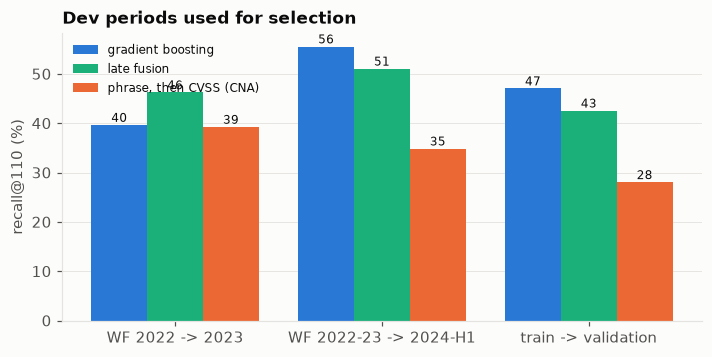

In [9]:
sd = T("05d_sensitivity_dev"); sd["model"] = sd["model"].str.replace(" (headline)", "", regex=False)   # old label from before Decision 12
p = sd[sd["variant"] == "base (as in 05b)"].set_index("model")[["wf_2023@110", "wf_2024h1@110", "val@110", "selection", "worst"]]
rule = b5.loc["phrase, then CVSS (CNA)"]; p.loc["phrase, then CVSS (CNA)"] = [rule["WF 2023"], rule["WF 2024-H1"], pt(rule["val recall@110 [CI] (ensemble for nets)"]), rule["selection (3-period mean)"], rule["worst period"]]
display(p); display(sd.set_index(["variant", "model"])[["selection", "worst"]])
fig, ax = plt.subplots(figsize=(7.5, 3.4)); x = np.arange(3); w = 0.27
for j, (m, c) in enumerate([("gradient boosting", BLUE), ("late fusion", AQUA), ("phrase, then CVSS (CNA)", ORANGE)]):
    v = p.loc[m, ["wf_2023@110", "wf_2024h1@110", "val@110"]].astype(float).to_numpy()
    ax.bar(x + (j - 1) * w, v, w, color=c, label=m.replace(" (headline)", ""))
    for xi, vi in zip(x, v): ax.annotate(f"{vi:.0f}", (xi + (j - 1) * w, vi), ha="center", xytext=(0, 2), textcoords="offset points", fontsize=8)
ax.set_xticks(x, ["WF 2022 -> 2023", "WF 2022-23 -> 2024-H1", "train -> validation"]); ax.grid(axis="x", visible=False)
ax.set_ylabel("recall@110 (%)"); ax.legend(frameon=False, fontsize=8); ax.set_title("Dev periods used for selection", loc="left"); save(fig, "00_06_selection")

**Takeaway**: Gradient boosting and late fusion are tied on dev (47.4 vs 46.7). The fusion was steadier across periods (worst 42.6 vs 39.7), but less robust to the uncertain-phrase check (−2.0 vs +0.4 for gradient boosting) and weaker on validation. **Gradient boosting became the headline on dev evidence only, before any test label was seen (Decision 12).** Both were scored on test.

## 9. Test results (Phase 6, run once) and the EPSS comparison
Test = 2025-01-01 → 2026-08-20, 102,561 CVEs, 294 exploited. Frozen models, hash-checked. EPSS (FIRST) is the
industry score; caveats: its first score usually appears the day **after** publication (lookahead), it predicts
30-day activity (different target), v4 replaced v3 inside the test period, and it is **assumed** to use KEV.

,recall@110 [95% CI],recall@305 [95% CI],PR-AUC
method,,,
gradient boosting (headline),33.7 [28–39],49.3 [44–55],0.053
late fusion (alternative),29.3 [24–35],48.0 [43–54],0.048
"phrase, then CVSS (CNA)",25.2 [20–30],42.2 [36–48],0.042
CVSS (CNA) ranking,18.6 [14–23],36.1 [30–41],0.014
generous CVSS (fallback) ranking,17.8 [13–22],31.6 [26–37],0.015
"EPSS (first score, <=7 d after pub)",29.6 [24–35],45.4 [40–51],0.069
EPSS (score by day 1),29.6 [24–35],45.1 [39–51],0.069
EPSS (day-0 score only),5.1 [3–8],9.9 [7–14],0.003
random,NaN,NaN,0.003


,difference [95% CI],P(headline better)
headline minus,,
late fusion (alternative),"+4.3 [-1.0, +9.1]",0.9390
"phrase, then CVSS (CNA)","+8.5 [+1.7, +15.3]",0.9890
CVSS (CNA) ranking,"+15.1 [+8.8, +21.5]",1.0000
generous CVSS (fallback) ranking,"+15.8 [+8.9, +22.4]",1.0000
"EPSS (first score, <=7 d after pub)","+4.1 [-2.7, +10.5]",0.8620
EPSS (score by day 1),"+4.1 [-2.7, +10.5]",0.8605
EPSS (day-0 score only),"+28.5 [+22.2, +34.5]",1.0000


,patches/month,rule recall %,rule precision %,headline recall % at same K,late fusion recall % at same K
rule,,,,,
CVSS>=9 (CNA),385,41.2,1.6,51.7,55.4
CVSS>=7 (CNA),2068,77.6,0.6,87.8,91.5
phrase OR CVSS>=9 (CNA),387,47.3,1.8,51.7,55.4
generous CVSS>=9 (fallback),516,44.9,1.3,56.5,62.6


,all 294 exploited,185 not yet in KEV at EPSS date
method,,
gradient boosting (headline),33.7 [28–39],30.4 [24–37]
late fusion (alternative),29.3 [24–35],23.8 [17–29]
"phrase, then CVSS (CNA)",25.2 [20–30],29.4 [23–36]
CVSS (CNA) ranking,18.6 [14–23],22.1 [16–28]
"EPSS (first score, <=7 d after pub)",29.6 [24–35],14.6 [9–20]
EPSS (day-0 score only),5.1 [3–8],6.5 [3–10]


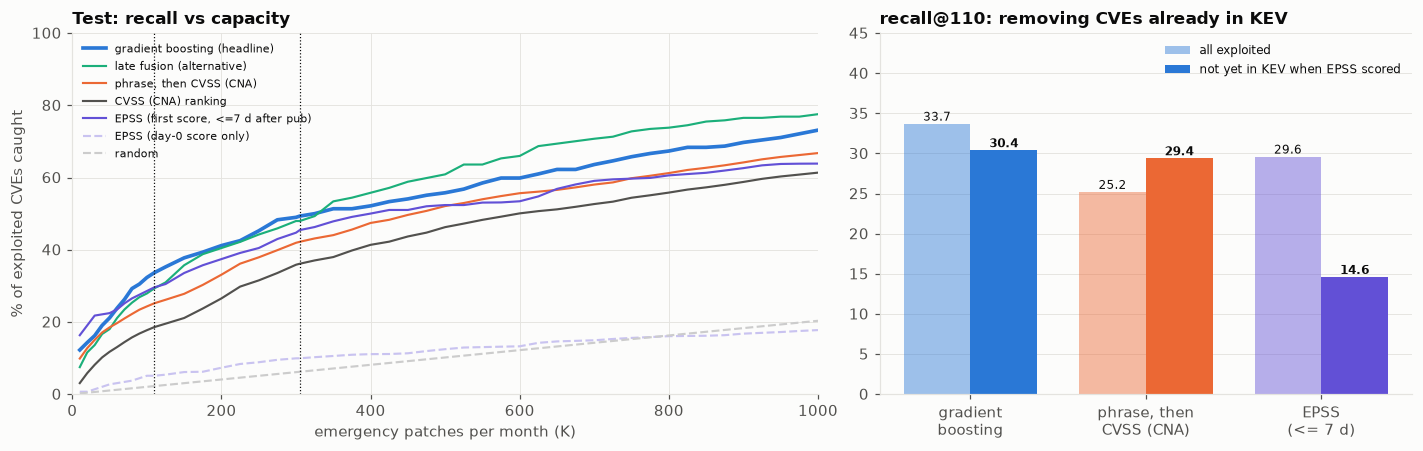

In [10]:
rec = T("06_recall").set_index("method"); dif = T("06_diffs"); own = T("06_own_capacity").set_index("rule"); curve = T("06_recall_vs_k").set_index("K per month")
nyk = T("06_not_yet_in_kev").set_index("EPSS variant defining the cut")
display(rec[["recall@110 [95% CI]", "recall@305 [95% CI]", "PR-AUC"]].round(3))
d = dif[dif["K"] == 110].set_index("headline minus")
display(d.assign(**{"difference [95% CI]": [f"{a:+.1f} [{b:+.1f}, {c:+.1f}]" for a, b, c in zip(d["diff (pts)"], d["CI lo"], d["CI hi"])]})[["difference [95% CI]", "P(headline better)"]])
display(own.round(1))
methods = [HEAD, ALT, "phrase, then CVSS (CNA)", "CVSS (CNA) ranking", EPSS7, "EPSS (day-0 score only)"]
display(pd.DataFrame({"all 294 exploited": rec.loc[methods, "recall@110 [95% CI]"],
                      "185 not yet in KEV at EPSS date": [nyk.loc[EPSS7, f"{m} @110"] for m in methods]}))
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [1.4, 1]})
COL = {HEAD: BLUE, ALT: AQUA, "phrase, then CVSS (CNA)": ORANGE, "CVSS (CNA) ranking": INK2, EPSS7: VIOLET, "EPSS (day-0 score only)": "#c9c3f0", "random": "#cccccc"}
for m in COL:
    axes[0].plot(curve.index, 100 * curve[m], color=COL[m], lw=2.4 if m == HEAD else 1.4, ls="--" if m in ("random", "EPSS (day-0 score only)") else "-", label=m)
for k in (110, 305): axes[0].axvline(k, color=INK, lw=0.8, ls=":")
axes[0].set(xlim=(0, 1000), ylim=(0, 100), xlabel="emergency patches per month (K)", ylabel="% of exploited CVEs caught")
axes[0].legend(frameon=False, fontsize=7.5, loc="upper left"); axes[0].set_title("Test: recall vs capacity", loc="left")
mm = [HEAD, "phrase, then CVSS (CNA)", EPSS7]; x = np.arange(3); w = 0.38
a = [pt(rec.loc[m, "recall@110 [95% CI]"]) for m in mm]; b_ = [pt(nyk.loc[EPSS7, f"{m} @110"]) for m in mm]
axes[1].bar(x - w/2, a, w, color=[COL[m] for m in mm], alpha=0.45, label="all exploited"); axes[1].bar(x + w/2, b_, w, color=[COL[m] for m in mm], label="not yet in KEV when EPSS scored")
for xi, (u, v) in enumerate(zip(a, b_)):
    axes[1].annotate(f"{u:.1f}", (xi - w/2, u), ha="center", xytext=(0, 2), textcoords="offset points", fontsize=8); axes[1].annotate(f"{v:.1f}", (xi + w/2, v), ha="center", xytext=(0, 2), textcoords="offset points", fontsize=8, weight="bold")
axes[1].set_xticks(x, ["gradient\nboosting", "phrase, then\nCVSS (CNA)", "EPSS\n(<= 7 d)"]); axes[1].grid(axis="x", visible=False); axes[1].set_ylim(0, 45)
axes[1].legend(frameon=False, fontsize=8); axes[1].set_title("recall@110: removing CVEs already in KEV", loc="left")
fig.tight_layout(); save(fig, "00_07_test_results")

**Takeaway**: **On 20 unseen months, gradient boosting caught 33.7% [28–39] of exploited CVEs at 110 patches a month**, vs 25.2% for the best rule (+8.5 [+1.7, +15.3], P 99%) and 18.6% for CVSS ranking (+15.1). It leads every day-0 rule at every capacity from 10 to 1,000 a month. **At the CVSS ≥ 9 rule's own 385 patches a month it catches 51.7% vs 41.2%.** Against **EPSS** it is ahead but not clearly (+4.1 [−2.7, +10.5]). EPSS is better at ≤ 50 patches a month, and only 30% of CVEs have an EPSS score on publication day. **On exploited CVEs not yet in KEV when EPSS scored them (185 of 294), EPSS falls to 14.6% while the model keeps 30.4%.** EPSS's apparent strength leans on CVEs already listed. Test recall is below validation (47.1%): see drift.

## 10. Explanations (SHAP) and drift
> ⚠️ **Post-test exploratory analysis**: designed after the test results were seen; it explains them and changes no reported number.

SHAP = permutation SHAP on the frozen model's 22 raw inputs (the standard tree explainer mis-handles the model's
categorical CVSS splits), 2,000 random test CVEs. Drift = 2025 vs 2026 and a quarterly-retraining simulation that
respects the 90-day label delay (notebooks 06 §7–8, 07 §1–4).

,group,mean |SHAP| random CVEs,mean |SHAP| exploited CVEs
feature,,,
CNA (who published),who: vendor / CNA / CWE,0.787,0.896
vendor KEV entries (all time),KEV history (vendor/product),0.645,1.135
CVSS score (CNA),CVSS (CNA),0.405,0.660
description length,text: phrase + length,0.355,0.357
CVSS PR,CVSS (CNA),0.353,0.370
CWE (CNA),who: vendor / CNA / CWE,0.305,0.268
vendor (or CNA),who: vendor / CNA / CWE,0.210,0.131
days since vendor's last KEV entry,KEV history (vendor/product),0.197,0.251
CVSS UI,CVSS (CNA),0.147,0.137


year,2025,2026
random CVEs,900.00,1100.00
exploited CVEs,159.00,135.00
KEV group mean |SHAP| (random),0.82,0.98
KEV group share of all |SHAP| %,20.98,23.47
"KEV group mean SHAP, exploited",1.06,1.04
"KEV group mean SHAP, non-exploited (random)",0.00,0.23
% of non-exploited with KEV push > +1,18.75,26.64
% of exploited with KEV push > +1,54.09,59.26
rank of 'vendor KEV entries (365 d)',16.00,17.00


,months,CVEs / month,exploited / month,K=110 as % of monthly CVEs,CVSS>=9 (CNA) / month,CVEs from vendors with earlier KEV entries / month
period,,,,,,
dev 2022-24,36,2606.7,8.9,4.2,123.8,695.7
2025,12,4012.5,13.2,2.7,237.5,1246.2
2026,8,6801.4,16.9,1.6,606.0,2375.8


,positives,frozen @110,rolling @110,rolling - frozen (pts),diff CI
period,,,,,
2025,159,41.9 [34–50],37.5 [30–45],-4.402516,"[-9.7, +0.7]"
2026,135,23.9 [17–32],31.3 [24–40],7.394547,"[+0.0, +15.2]"
all test,294,33.7 [28–39],34.7 [29–40],1.014503,"[-3.3, +5.6]"


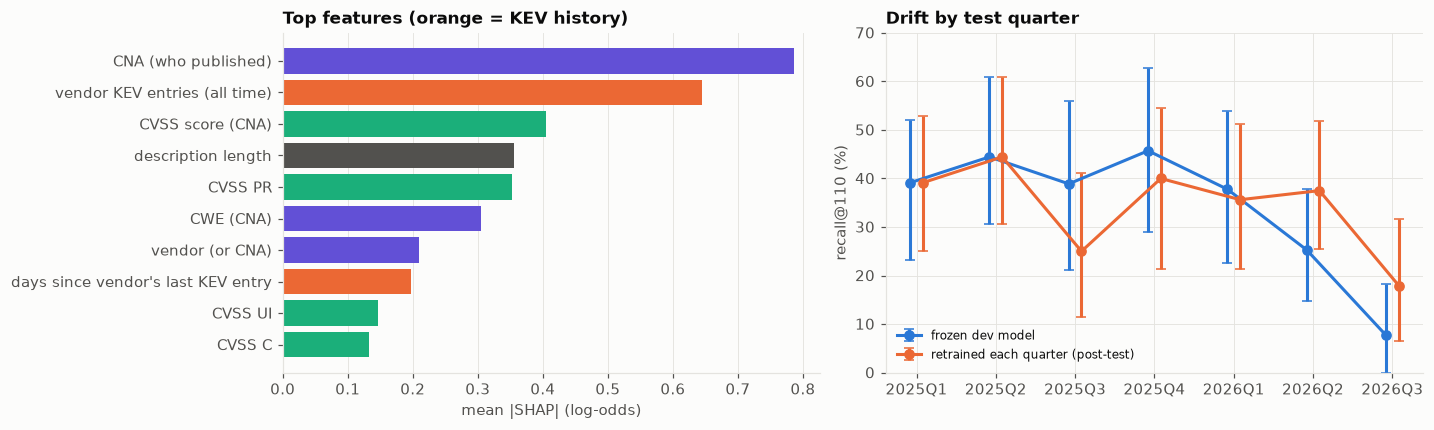

In [11]:
imp = T("07_shap_importance").head(10); ky = T("07_shap_kev_by_year").set_index("year"); dy = T("06x_drift_by_year").set_index("year")
vol = T("06x_drift_volume").set_index("period"); roll = T("06x_rolling_retrain"); q = roll[roll["period"].str.contains("Q")].reset_index(drop=True)
display(imp.set_index("feature"))
display(ky.T.round(2))
display(vol.round(1))
display(roll.set_index("period").loc[["2025", "2026", "all test"], ["positives", "frozen @110", "rolling @110", "rolling - frozen (pts)", "diff CI"]])
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
t10 = imp.iloc[::-1]; axes[0].barh(t10["feature"], t10["mean |SHAP| random CVEs"], color=[ORANGE if "KEV" in g else AQUA if "CVSS" in g else VIOLET if "who" in g else INK2 for g in t10["group"]])
axes[0].set_xlabel("mean |SHAP| (log-odds)"); axes[0].grid(axis="y", visible=False); axes[0].set_title("Top features (orange = KEV history)", loc="left")
xq = np.arange(len(q))
for nm, c, off in [("frozen", BLUE, -0.08), ("rolling", ORANGE, 0.08)]:
    axes[1].errorbar(xq + off, q[nm], yerr=[q[nm] - q[f"{nm} lo"], q[f"{nm} hi"] - q[nm]], fmt="o-", color=c, capsize=3, lw=2,
                     label="frozen dev model" if nm == "frozen" else "retrained each quarter (post-test)")
axes[1].set_xticks(xq, q["period"]); axes[1].set_ylim(0, 70); axes[1].set_ylabel("recall@110 (%)"); axes[1].legend(frameon=False, fontsize=8)
axes[1].set_title("Drift by test quarter", loc="left"); fig.tight_layout(); save(fig, "00_08_shap_drift")

**Takeaway**: **The model reads who is affected and whether attackers already target that vendor, then severity.** The top drivers are publisher (CNA), the vendor's KEV history and CNA CVSS. **Recall fell from 41.9% (2025) to 23.9% (2026)**, with 7.7% in Jul–Aug 2026. EPSS stayed flat at 29.6%. Two causes: CVE volume rose to 6,800 a month (K = 110 is now 1.6% of a month), and CVEs from vendors with KEV history went from 1,246 to 2,376 a month. The KEV-history push for non-exploited CVEs rose (share pushed > +1 log-odds: 18.8% → 26.6%), so look-alikes crowd the top 110. **Retraining every quarter (90-day label delay respected) recovers part of it: 2026 recall 31.3% vs 23.9%** (+7.4 [+0.0, +15.2]); over all test it is +1.0.

## 11. Business impact
The savings below assume the model is **retrained every quarter** (the frozen model's advantage disappeared in 2026,
Section 10); frozen-model numbers are shown for reference. **Change the assumptions and re-run.**

In [12]:
# ================= ASSUMPTIONS (edit me) =================
HOURS_PER_EMERGENCY_PATCH = 6.0     # out-of-cycle patch: triage, test, change approval, deploy, verify
COST_PER_HOUR_USD = 100.0           # fully loaded analyst/engineer hour
SHARE_OF_FEED = 1.0                 # share of all NVD CVEs that affect your estate (1.0 = whole feed, as studied)
# =========================================================

,period,rule,rule patches / month,rule recall %,GB rolling-retrain patches / month to match,saved / month (retrained),hours saved / year (retrained),USD saved / year (retrained),GB (frozen) patches / month to match,"saved / month (frozen, reference)"
0,all test,CVSS>=9 (CNA),384.9,41.2,148.0,236.9,17056.8,1705680.0,198.0,186.9
1,all test,phrase OR CVSS>=9 (CNA),386.6,47.3,205.0,181.6,13071.6,1307160.0,265.0,121.6
2,2025,CVSS>=9 (CNA),237.5,36.5,106.0,131.5,9468.0,946800.0,83.0,154.5
3,2025,phrase OR CVSS>=9 (CNA),239.7,45.9,147.0,92.7,6672.0,667200.0,155.0,84.7
4,2026 (Jan-Aug),CVSS>=9 (CNA),606.0,46.7,302.0,304.0,21888.0,2188800.0,569.0,37.0
5,2026 (Jan-Aug),phrase OR CVSS>=9 (CNA),606.9,48.9,330.0,276.9,19935.0,1993500.0,630.0,-23.1


Sensitivity: matching the CVSS>=9 (CNA) rule's recall with fewer emergency patches


,"hours saved / yr, retrained (all test)","USD saved / yr, retrained (all test)","USD saved / yr, retrained (2026 rate)","USD saved / yr, frozen (all test, reference)","USD saved / yr, frozen (2026 rate, reference)"
hours per patch,,,,,
2,5686.0,568560.0,729600.0,448560.0,88800.0
4,11371.0,1137120.0,1459200.0,897120.0,177600.0
6,17057.0,1705680.0,2188800.0,1345680.0,266400.0
8,22742.0,2274240.0,2918400.0,1794240.0,355200.0
10,28428.0,2842800.0,3648000.0,2242800.0,444000.0


,patches / month,GB recall %,comparator recall %,extra exploited caught / year
comparison,,,,
"GB vs phrase, then CVSS (CNA) ranking, both at K = 110/month",110.0,33.7,25.2,14.9
"GB vs CVSS (CNA) ranking, both at K = 110/month",110.0,33.7,18.6,26.6
"GB vs CVSS>=9 (CNA) rule, at the rule's own capacity",384.9,51.7,41.2,18.6
"GB vs phrase OR CVSS>=9 (CNA) rule, at the rule's own capacity",386.6,51.7,47.3,7.8


ransomware-linked exploited CVEs (n = 43), recall@110:


,recall@110 [95% CI],recall@385 [95% CI]
method,,
gradient boosting (headline),42.2 [27–57],65.1 [51–79]
late fusion (alternative),37.2 [24–52],74.4 [59–86]
"phrase, then CVSS (CNA)",26.7 [13–41],55.7 [39–71]
CVSS (CNA) ranking,24.6 [11–39],53.5 [37–70]
"EPSS (first score, <=7 d after pub)",27.9 [15–42],51.2 [36–67]
EPSS (score by day 1),27.9 [15–42],51.2 [36–67]


,period,model,fixed K=110: recall %,volume-scaled 4.22%: recall %,"fixed K, same total patches: recall %",scaled: avg patches / month,extra hours / year vs K=110
0,2025,frozen,41.9,49.7,48.1,169.3,4271.2
1,2025,rolling quarterly retrain,37.5,49.1,50.3,169.3,4271.2
2,2026 (Jan-Aug),frozen,23.9,34.1,37.0,287.0,12744.6
3,2026 (Jan-Aug),rolling quarterly retrain,31.3,44.4,45.9,287.0,12744.6
4,all test,frozen,33.7,42.5,41.8,216.4,7660.5
5,all test,rolling quarterly retrain,34.7,46.9,48.0,216.4,7660.5


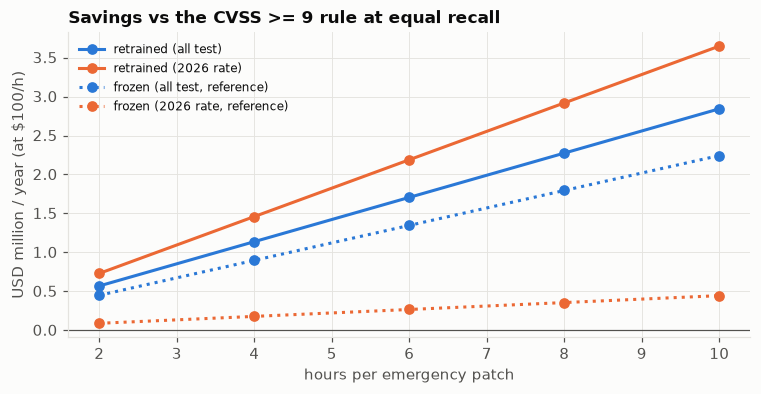

In [13]:
sr = T("07_same_recall"); sc_ = T("07_same_capacity").set_index("comparison"); pol = T("07_policy"); rw = T("07_ransomware")
sr["saved / month (retrained)"] = (sr["rule patches / month"] - sr["GB rolling-retrain patches / month to match"]) * SHARE_OF_FEED
sr["saved / month (frozen, reference)"] = (sr["rule patches / month"] - sr["GB (frozen) patches / month to match"]) * SHARE_OF_FEED
sr["hours saved / year (retrained)"] = sr["saved / month (retrained)"] * 12 * HOURS_PER_EMERGENCY_PATCH
sr["USD saved / year (retrained)"] = sr["hours saved / year (retrained)"] * COST_PER_HOUR_USD
display(sr[["period", "rule", "rule patches / month", "rule recall %", "GB rolling-retrain patches / month to match", "saved / month (retrained)",
            "hours saved / year (retrained)", "USD saved / year (retrained)", "GB (frozen) patches / month to match", "saved / month (frozen, reference)"]].round(1))
hours = [2, 4, 6, 8, 10]
main = sr[(sr["period"] == "all test") & (sr["rule"] == "CVSS>=9 (CNA)")].iloc[0]; y26 = sr[(sr["period"] == "2026 (Jan-Aug)") & (sr["rule"] == "CVSS>=9 (CNA)")].iloc[0]
sens = pd.DataFrame({"hours per patch": hours,
    "hours saved / yr, retrained (all test)": [main["saved / month (retrained)"] * 12 * h for h in hours],
    "USD saved / yr, retrained (all test)": [main["saved / month (retrained)"] * 12 * h * COST_PER_HOUR_USD for h in hours],
    "USD saved / yr, retrained (2026 rate)": [y26["saved / month (retrained)"] * 12 * h * COST_PER_HOUR_USD for h in hours],
    "USD saved / yr, frozen (all test, reference)": [main["saved / month (frozen, reference)"] * 12 * h * COST_PER_HOUR_USD for h in hours],
    "USD saved / yr, frozen (2026 rate, reference)": [y26["saved / month (frozen, reference)"] * 12 * h * COST_PER_HOUR_USD for h in hours]}).set_index("hours per patch")
print("Sensitivity: matching the CVSS>=9 (CNA) rule's recall with fewer emergency patches"); display(sens.round(0))
display(sc_.round(1))
print("ransomware-linked exploited CVEs (n = 43), recall@110:"); display(rw[rw["subset"] == "ransomware-linked exploited"].set_index("method")[["recall@110 [95% CI]", "recall@385 [95% CI]"]])
display(pol.round(1))
fig, ax = plt.subplots(figsize=(8, 3.6))
for col_, c, ls in [("USD saved / yr, retrained (all test)", BLUE, "-"), ("USD saved / yr, retrained (2026 rate)", ORANGE, "-"),
                    ("USD saved / yr, frozen (all test, reference)", BLUE, ":"), ("USD saved / yr, frozen (2026 rate, reference)", ORANGE, ":")]:
    ax.plot(sens.index, sens[col_] / 1e6, ls, color=c, marker="o", lw=2, label=col_.replace("USD saved / yr, ", ""))
ax.axhline(0, color=INK2, lw=0.8); ax.set_xlabel("hours per emergency patch"); ax.set_ylabel(f"USD million / year (at ${COST_PER_HOUR_USD:.0f}/h)")
ax.legend(frameon=False, fontsize=8); ax.set_title("Savings vs the CVSS >= 9 rule at equal recall", loc="left"); save(fig, "00_09_business")

**Takeaway**: **Conditional on quarterly retraining**, matching the CVSS ≥ 9 rule's coverage (41.2%) takes **148 patches a month instead of 385**. That is **~237 fewer emergency patches a month, ~17,000 analyst hours (~$1.7M) a year** at 6 h and $100/h. The range is $0.57M at 2 h per patch to $2.84M at 10 h, and $0.73–3.65M at 2026 volumes. **Without retraining the 2026 saving almost disappears** ($0.09–0.44M; the frozen model needs 569 of the rule's 606 patches). At equal capacity the model catches **+15 to +27 more exploited CVEs a year** at 110 patches a month. On **ransomware-linked** CVEs it catches 42.2% vs 24.6–27.9% for the rules and EPSS (n = 43, wide CIs). Sizing capacity to ~4.2% of monthly CVEs plus retraining reaches 46.9% recall (44.4% in 2026) for about +7,700 analyst hours a year. These are whole-NVD-feed numbers. Scale by `SHARE_OF_FEED` for a real estate.

## 12. Limitations and next steps
**Limitations**
* **The baseline policy is assumed.** "Patch CVSS ≥ 9" is common severity-based practice, not a verified policy of a
  specific organisation. The conclusion does not rest on it: the model leads the day-0 rules at every K from 10 to
  1,000 patches a month (Section 9 curve), and at each rule's own capacity (CVSS ≥ 9, CVSS ≥ 7, phrase-or-CVSS ≥ 9,
  hindsight CVSS ≥ 9). Only EPSS (with a one-day lookahead) is ahead, and only at 50 patches a month or fewer.
* **Label = CISA KEV within 90 days**: CISA's selection (evidence required, US-government-relevant products). Exploits
  never reported to CISA count as "not exploited"; some "false alarms" were added to KEV later (3% of top-10 false alarms).
* **Day-0 is approximate**: CNAs later changed their own CVSS for 5.5% of exploited vs 1.9% of other CVEs (−0.8 points
  when using the first known vector); description edits are label-correlated (history audited only for a sample).
* **EPSS comparison**: lookahead favours EPSS, different target, v3→v4 switch, EPSS's use of KEV is an assumption
  (documentation not reachable from the project sandbox).
* **Drift**: recall fell from 41.9% (2025) to 23.9% (2026) at a fixed K = 110; savings require quarterly retraining
  and a capacity sized to CVE volume (both evaluated post-test, exploratory).
* **Small numbers**: 294 exploited test CVEs; quarterly CIs ±15–20 points; ransomware subset 43 CVEs.
* **Calibration**: probabilities over-predict on average after the base rate fell; the demo shows a within-month
  percentile as primary output and an indicative probability (Platt on time-ordered out-of-fold scores).
* **Whole NVD feed**: an organisation sees only CVEs affecting its estate (`SHARE_OF_FEED`), and exploitation of its
  own assets is what matters.

**Next steps**
1. Retrain quarterly with the 90-day label delay; re-check K against monthly volume each quarter.
2. Monitor recall on newly KEV-listed CVEs monthly; alert when the KEV-history signal saturates (2026 pattern).
3. Pilot on the organisation's own asset inventory (product matching), where precision per patch is much higher.
4. Add early public signals available within 24 h (vendor advisories, exploit PoC references at publication time),
   carefully timestamped to avoid leakage.
5. Re-evaluate against EPSS with day-matched scores and a KEV-free target.

In [14]:
dep = json.loads((ROOT / "outputs" / "models" / "deploy_models.json").read_text()); cal = json.loads((ROOT / "outputs" / "models" / "calibrator_deploy.json").read_text())
fc = T("06_final_comparison").set_index("method"); display(fc)
print(f"deployment/demo model: {dep['n']:,} CVEs / {dep['positives']} positives, sha256 {dep['sha256']['hgb'][:16]} (not used for any reported number)")
print(f"demo indicative probability: Platt on time-ordered OOF scores, Brier {cal['Brier leave-one-half-year-out']:.5f} vs constant {cal['Brier constant']:.5f} (leave-one-half-year-out)")

,type,val recall@110,test recall@110 [95% CI],test recall@305 [95% CI],test 2025 @110,test 2026 @110,not yet in KEV @110,test PR-AUC
method,,,,,,,,
gradient boosting (headline),model (headline),47.1 [36–60],33.7 [28–39],49.3 [44–55],41.9 [34–50],23.9 [17–32],30.4 [24–37],0.053
late fusion (alternative),model (alternative),42.6 [30–55],29.3 [24–35],48.0 [43–54],39.1 [31–47],17.8 [12–25],23.8 [17–29],0.048
"EPSS (first score, <=7 d after pub)",benchmark (lookahead),36.8 [25–48],29.6 [24–35],45.4 [40–51],29.6 [23–37],29.6 [21–37],14.6 [9–20],0.069
EPSS (score by day 1),benchmark,36.8 [25–49],29.6 [24–35],45.1 [39–51],29.6 [23–37],29.6 [21–37],14.6 [9–20],0.069
"phrase, then CVSS (CNA)",day-0 rule (best),28.1 [17–38],25.2 [20–30],42.2 [36–48],29.5 [22–37],20.0 [13–27],29.4 [23–36],0.042
CVSS (CNA) ranking,day-0 rule (today),23.7 [13–33],18.6 [14–23],36.1 [30–41],19.2 [13–26],17.8 [11–25],22.1 [16–28],0.014
generous CVSS (fallback) ranking,rule with hindsight,15.1 [6–25],17.8 [13–22],31.6 [26–37],NaN,NaN,20.3 [14–27],0.015
EPSS (day-0 score only),benchmark (like-for-like),2.9 [0–8],5.1 [3–8],9.9 [7–14],NaN,NaN,6.5 [3–10],0.003
random,reference,3.5,2.2,6.2,NaN,NaN,NaN,0.003


deployment/demo model: 196,403 CVEs / 613 positives, sha256 627441c1e8435f73 (not used for any reported number)
demo indicative probability: Platt on time-ordered OOF scores, Brier 0.00299 vs constant 0.00307 (leave-one-half-year-out)


**Takeaway**: **A day-0 gradient-boosting ranking, chosen on dev before the test set was opened, beats every day-0 rule on 20 unseen months.** It catches 33.7% vs 25.2% of exploited CVEs at 110 patches a month, and 51.7% vs 41.2% at the CVSS ≥ 9 rule's own workload. It is level-to-ahead of EPSS (about 2x EPSS on CVEs not yet in KEV). The gains hold only if the model is **retrained quarterly** and capacity is **re-checked against CVE volume**: both evaluated after the test, as operating recommendations.